This is the cutdown companion Jupyter Notebook of Chapter 7, Quantum Machine Learning for Molecular Prediction, of the second edition of the book titled: "Quantum Chemistry and Computing for the Curious: Illustrated with Python and Qiskit® code" and with ISBN-13: 978-1803243900. Copyright © 2026, Keeper L. Sharkey and Alain Chancé.

The following MIT license only applies to the code, and not to the text and images. The authors are not granting a license to replicate or reuse the text and images in the companion Jupyter notebook.

# MIT License

Copyright (c) 2026 Packt

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.

# 7. Quantum Machine Learning for Molecular Prediction

# Technical requirements
A companion Jupyter notebook for this chapter can be downloaded from GitHub at  https://github.com/PacktPublishing/Quantum-Chemistry-and-Computing-for-the-Curious-Second-Edition. For more information about how to install Qiskit, please refer to the IBM Install Qiskit documentation, https://quantum.cloud.ibm.com/docs/en/guides/install-qiskit, and in Robert Loredo's book [Loredo_Qiskit].

The companion Jupyter notebook automatically installs the following list of libraries:
* Numerical Python (NumPy) [NumPy], an open-source Python library that is used in almost every field of science and engineering.
* Qiskit [Qiskit], an open-source SDK for working with quantum computers at the level of pulses, circuits, and application modules.
* Qiskit Runtime IBM Client provides the interface to access the Qiskit Runtime service on IBM Quantum Platform.
* Qiskit visualization support to enable the use of visualizations and Jupyter notebooks.
* Python-based Simulations of Chemistry Framework (PySCF) [PySCF], an open-source collection of electronic structure modules powered by Python.
* Quantum Toolbox in Python (QuTiP) [QuTiP], a general framework for solving quantum mechanics problems such as systems composed of few-level quantum systems and harmonic oscillators.
* Atomic Simulation Environment (ASE) [ASE_0], a set of tools and Python modules for setting up, manipulating, running, visualizing, and analyzing atomistic simulations. The code is freely available under the GNU LGPL license.
* PyQMC [PyQMC], a Python module that implements real-space quantum Monte Carlo techniques. It is primarily meant to interoperate with PySCF.
* h5py [h5py] package, a Pythonic interface to the HDF5 binary data format.
* SciPy [SciPy], a Python module that contains a large number of probability distributions, summary and frequency statistics, correlation functions and statistical tests, masked statistics, kernel density estimation, quasi-Monte Carlo functionality, and more.
* scikit-learn, (often written sklearn) is a widely used open-source Python library for machine learning. It provides efficient and easy-to-use tools for building, training, and evaluating machine-learning models.
* Qiskit Machine Learning [QML_1] introduces fundamental computational building blocks, such as Quantum Kernels and Quantum Neural Networks, used in various applications including classification and regression.
* RDKit, a collection of cheminformatics and machine-learning software written in C++ and Python.


# New in the second edition
## Qiskit Machine Learning 0.9.0
## Patched optimizer method of Qiskit Machine Learning's NeuralNetworkRegressor

## Installing NumPy, and Qiskit and importing various modules
### Install NumPy with the following command:

In [1]:
pip install numpy

Note: you may need to restart the kernel to use updated packages.


### Install Qiskit with the following command:

In [2]:
pip install qiskit

Note: you may need to restart the kernel to use updated packages.


### Install the IBM Runtime client

In [3]:
pip install qiskit-ibm-runtime

Note: you may need to restart the kernel to use updated packages.


### Install Qiskit visualization support with the following command:

In [4]:
pip install 'qiskit[visualization]'

Note: you may need to restart the kernel to use updated packages.


## Install Qiskit Aer with the following command:

In [5]:
pip install qiskit-aer

Note: you may need to restart the kernel to use updated packages.


### Install qiskit.utils with the following command:

In [6]:
pip install qiskit.utils

Note: you may need to restart the kernel to use updated packages.


### Install Qiskit Algorithms with the following command:

In [7]:
pip install qiskit_algorithms

Note: you may need to restart the kernel to use updated packages.


### Install PySCF with the following command:

In [8]:
pip install pyscf

Note: you may need to restart the kernel to use updated packages.


### Install SciPy with the following command:

In [9]:
pip install scipy

Note: you may need to restart the kernel to use updated packages.


### Install scikit-learn with the following command:

In [10]:
pip install -U scikit-learn

Note: you may need to restart the kernel to use updated packages.


### Install Qiskit Machine Learning with the following command:

In [11]:
pip install qiskit-machine-learning

Note: you may need to restart the kernel to use updated packages.


### Install RDKit with the following command:

In [12]:
pip install rdkit

Note: you may need to restart the kernel to use updated packages.


### Import Qiskit Runtime primitives with the following commands:

In [13]:
# Import Qiskit Runtime primitives
from qiskit.primitives import BaseSamplerV2 as BaseSampler, StatevectorSampler as Sampler
from qiskit.primitives import BaseEstimatorV2 as BaseEstimator, StatevectorEstimator as Estimator

### Import the required functions and class methods with the following commands:

In [14]:
from qiskit.visualization import array_to_latex, plot_bloch_vector, plot_bloch_multivector, plot_state_qsphere, plot_state_city
from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit, transpile
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

### Import Qiskit Aer simulator and NoiseModel class with the following commands:

In [15]:
import qiskit_aer
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, pauli_error
from qiskit.result import Counts

### Import various algorithms with the following commands:

In [16]:
from qiskit_algorithms.optimizers import ADAM, COBYLA, L_BFGS_B, NELDER_MEAD, SPSA, SLSQP, QNSPSA
from qiskit_algorithms.gradients import ParamShiftEstimatorGradient

###  Import various libraries with the following commands:

In [17]:
import qiskit.quantum_info as qi
from qiskit.quantum_info import SparsePauliOp, Statevector

### Import various quantum circuits with the following commands:

In [18]:
from qiskit.circuit.library import Initialize, n_local, PauliEvolutionGate
from qiskit.circuit.library import zz_feature_map, pauli_feature_map, efficient_su2, RealAmplitudes

### Import the PySCF gto and scf libraries with the following command:

In [19]:
from pyscf import gto, scf

### Import the math libraries with the following commands:

In [20]:
import cmath
import math

### Import time and datetime with the following command:

In [21]:
import time, datetime

### Import pandas and os.path with the following commands:

In [22]:
import pandas as pd
import os.path

### Import NumPy with the following command:

In [23]:
import numpy as np
from numpy.polynomial.polynomial import Polynomial

### Import Matplotlib with the following command:

In [24]:
import matplotlib.pyplot as plt

### Import scikit-learn libraries with the following commands:

In [25]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, KernelPCA
from sklearn.svm import SVC, SVR
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.cluster import KMeans
from sklearn.kernel_ridge import KernelRidge

### Import Qiskit Machine Learning libraries with the following commands:

In [26]:
from qiskit_machine_learning.utils import algorithm_globals

from qiskit_machine_learning.algorithms import VQC
from qiskit_machine_learning.datasets import ad_hoc_data

from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.algorithms import NeuralNetworkRegressor

### Import Chem, Descriptors, AllChem, rdMolDescriptors with the following commands:

In [27]:
from rdkit import Chem
from rdkit.Chem import Descriptors, AllChem, rdMolDescriptors, rdFingerprintGenerator

### Import warnings and ignore Sparse Efficiency Warning

In [28]:
import warnings
from scipy.sparse import SparseEfficiencyWarning

warnings.filterwarnings("ignore", category=SparseEfficiencyWarning)

# 7.1. Introduction to Quantum Machine Learning (QML)
## 7.1.1. Quantum Kernel Pipeline

## 7.1.2. Patched optimizer method of Qiskit Machine Learning's NeuralNetworkRegressor

In [29]:
def patch_optimizer(optimizer, callback):
    """
    Patch either qiskit.algorithms.optimizers (optimize API)
    or qiskit_algorithms.optimizers (minimize API)
    so that the callback fires on every objective evaluation.
    """
    
    if callback is None:
        return optimizer

    has_optimize = hasattr(optimizer, "optimize")
    has_minimize = hasattr(optimizer, "minimize")

    # ------------------------------------------------
    # Case 1: deprecated qiskit.algorithms.optimizers
    # ------------------------------------------------
    if has_optimize:
        original_optimize = optimizer.optimize

        def patched_optimize(num_vars, objective_function, initial_point):
            eval_count = 0

            def wrapped_obj(params):
                nonlocal eval_count
                val = objective_function(params)
                if callback is not None:
                    callback(eval_count, params, val, None)
                eval_count += 1
                return val

            return original_optimize(num_vars, wrapped_obj, initial_point)

        optimizer.optimize = patched_optimize
        return optimizer

    # -------------------------------------------------------------
    # Case 2: Qiskit Algorithms 0.4.0 qiskit_algorithms.optimizers
    # -------------------------------------------------------------
    if has_minimize:
        original_minimize = optimizer.minimize

        def patched_minimize(fun, x0, *args, **kwargs):
            eval_count = 0

            def wrapped_fun(params):
                nonlocal eval_count
                val = fun(params)
                if callback is not None:
                    callback(eval_count, params, val, None)
                eval_count += 1
                return val

            return original_minimize(wrapped_fun, x0, *args, **kwargs)

        optimizer.minimize = patched_minimize
        return optimizer

    # -----------------------------
    # Unsupported optimizer
    # -----------------------------
    print("Optimizer does not expose optimize() or minimize().")
    return optimizer

## 7.1.3. QiskitKernelPipeline class

In [30]:
class QiskitQMLPipeline:
    def __init__(self, mode="kernel", max_qubits=12, max_pca=6, 
                 reps=1, test_size=0.2, random_state=0, 
                 optimizer=SPSA(maxiter=200),
                 entanglement_kernel='circular',
                 entanglement_QNN='linear',
                 callback=None):

        self.mode = mode
        self.max_qubits = max_qubits
        self.max_pca = max_pca
        self.reps = reps
        self.test_size = test_size
        self.random_state = random_state
        self.optimizer = optimizer
        self.entanglement_kernel = entanglement_kernel
        self.entanglement_QNN = entanglement_QNN
        self.callback = callback
        self.scaler = StandardScaler()
        self.y_scaler = StandardScaler()
        self.feature_map = None
        self.param_list = None
        self.qnn = None
        self.regressor = None


    # ----------------- internal helpers -----------------
    def _encode_state(self, x):
        fm = self.feature_map.assign_parameters(
            {p: v for p, v in zip(self.param_list, x)}
        )
        return Statevector.from_instruction(fm)

    def _kernel_matrix(self, X1, X2):
        n1, n2 = len(X1), len(X2)
        K = np.zeros((n1, n2))

        states1 = [self._encode_state(x) for x in X1]
        states2 = [self._encode_state(y) for y in X2]

        for i, psi_x in enumerate(states1):
            for j, psi_y in enumerate(states2):
                K[i, j] = np.abs(psi_x.data.conj().dot(psi_y.data))**2

        return K


    # ----------------- fit -----------------
    def fit(self, X, y):
        indices = np.arange(len(X))
        self.train_idx, self.test_idx = train_test_split(
            indices, test_size=self.test_size, random_state=self.random_state
        )

        self.X_train_raw = X[self.train_idx]
        self.X_test_raw  = X[self.test_idx]
        self.y_train_raw = y[self.train_idx]
        self.y_test_raw  = y[self.test_idx]

        X_train_scaled = self.scaler.fit_transform(self.X_train_raw)
        self.y_train = self.y_scaler.fit_transform(
            self.y_train_raw.reshape(-1, 1)
        ).ravel()

        max_dim = min(X_train_scaled.shape[0],
                      X_train_scaled.shape[1],
                      self.max_qubits)
        n_components = min(self.max_pca, max_dim)

        self.pca = PCA(n_components=n_components, whiten=True)
        X_train_reduced = self.pca.fit_transform(X_train_scaled)
        self.X_train = X_train_reduced

        num_qubits = X_train_reduced.shape[1]
        self.feature_map = pauli_feature_map(
            num_qubits,
            reps=self.reps,
            paulis=['Z'],
            entanglement=self.entanglement_kernel
        )
        self.param_list = list(self.feature_map.parameters)

        if self.mode == "kernel":
            self._fit_kernel()
        else:
            self._fit_estimator()


    # ----------------- kernel mode -----------------
    def _fit_kernel(self):
        K_train = self._kernel_matrix(self.X_train, self.X_train)
        self.clf = SVR(kernel='precomputed', C=1.0, epsilon=0.005)
        self.clf.fit(K_train, self.y_train)


    # ----------------- EstimatorQNN mode -----------------
    def _fit_estimator(self):
        num_qubits = self.feature_map.num_qubits
        ansatz = efficient_su2(num_qubits, reps=self.reps,
                               entanglement=self.entanglement_QNN)

        qc = QuantumCircuit(num_qubits)
        qc.compose(self.feature_map, inplace=True)
        qc.compose(ansatz, inplace=True)

        estimator = Estimator()
        gradient = ParamShiftEstimatorGradient(estimator)

        self.qnn = EstimatorQNN(
            estimator=estimator,
            circuit=qc,
            input_params=self.feature_map.parameters,
            weight_params=ansatz.parameters,
            gradient=gradient,
        )

        # Patch optimizer so callback works
        optimizer = self.optimizer
        if self.callback is not None:
            optimizer = patch_optimizer(self.optimizer, self.callback)

        # Train using Qiskit Machine Learning's NeuralNetworkRegressor
        self.regressor = NeuralNetworkRegressor(
            neural_network=self.qnn,
            loss='squared_error',
            optimizer=optimizer
        )
        self.regressor.fit(self.X_train, self.y_train)


    # ----------------- predict / score -----------------
    def predict(self, X_raw):
        X_scaled = self.scaler.transform(X_raw)
        X_reduced = self.pca.transform(X_scaled)

        if self.mode == "kernel":
            K_test = self._kernel_matrix(X_reduced, self.X_train)
            y_pred_scaled = self.clf.predict(K_test)
        else:
            y_pred_scaled = self.regressor.predict(X_reduced)

        return self.y_scaler.inverse_transform(
            y_pred_scaled.reshape(-1, 1)
        ).ravel()

    def score(self):
        y_pred = self.predict(self.X_test_raw)
        r2 = r2_score(self.y_test_raw, y_pred)
        mae = mean_absolute_error(self.y_test_raw, y_pred)
        print(f"R² = {r2:.4f}, MAE = {mae:.4f}")
        return r2


# 7.2. Preparing Molecular Datasets in Python

## 7.2.1. Python toy dataset: SMILES + optional IDs

In [31]:
smiles_list = [
"CC1=CC=CC=C1", "CCOC1=CC=CC=C1", "CCN(CC)CC", "CCOC(=O)C1=CC=CC=C1",
"CC1=CC=C(O)C=C1", "CC1=CC=C(N)C=C1", "CCOC(=O)N1CCCC1",
"CCN1CCCC1", "CCOC1=CC=CC=C1O", "CCOC1=CC=C(C)C=C1",
"CCOC1=CC=C(Cl)C=C1", "CCOC1=CC=C(F)C=C1", "CCOC1=CC=C(Br)C=C1",
"CCOC1=CC=C(CN)C=C1", "CCOC1=CC=C(CO)C=C1", "CCOC1=CC=C(C=O)C=C1",
"CCOC1=CC=C(C(=O)O)C=C1", "CCOC1=CC=C(C(=O)N)C=C1",
"CCOC1=CC=C(CN(C)C)C=C1", "CCOC1=CC=C(CCN)C=C1",
"CC1=CC=C(OCC)C=C1", "CC1=CC=C(OCCC)C=C1", "CC1=CC=C(OCCN)C=C1",
"CC1=CC=C(OCCO)C=C1", "CC1=CC=C(OCCCl)C=C1", "CC1=CC=C(OCCF)C=C1",
"CC1=CC=C(OCCBr)C=C1", "CC1=CC=C(OCCCN)C=C1", "CC1=CC=C(OCCC=O)C=C1",
"CC1=CC=C(OCCC(=O)O)C=C1",

"CN1CCCCC1", "CN1CCCC1", "CCN1CCCCC1", "CCN1CCCC1",
"COC1=CC=CC=C1", "COC1=CC=C(C)C=C1", "COC1=CC=C(O)C=C1",
"COC1=CC=C(N)C=C1", "COC1=CC=C(Cl)C=C1", "COC1=CC=C(F)C=C1",
"COC1=CC=C(Br)C=C1", "COC1=CC=C(CN)C=C1", "COC1=CC=C(CO)C=C1",
"COC1=CC=C(C=O)C=C1", "COC1=CC=C(C(=O)O)C=C1", "COC1=CC=C(C(=O)N)C=C1",

"CCOC(=O)N1CCCCC1", "CCOC(=O)N1CCCC1", "CCOC(=O)N1CCC1",
"CCOC(=O)N1CCNCC1", "CCOC(=O)N1CCOCC1",

"CCN(CC)C1=CC=CC=C1", "CCN(CC)C1=CC=C(C)C=C1",
"CCN(CC)C1=CC=C(O)C=C1", "CCN(CC)C1=CC=C(Cl)C=C1",
"CCN(CC)C1=CC=C(F)C=C1", "CCN(CC)C1=CC=C(Br)C=C1",

"CCOC1=CC=NC=C1", "CCOC1=CC=CN=C1", "COC1=CC=NC=C1",
"COC1=CC=CN=C1", "CCOC1=NC=CC=C1", "COC1=NC=CC=C1",

"CCN1C=NC2=CC=CC=C12", "CN1C=NC2=CC=CC=C12",
"CCN1C=NC2=CC=C(C)C=C12", "CN1C=NC2=CC=C(C)C=C12",

"CCOC1=CC=C2N=CC=CC2=C1", "COC1=CC=C2N=CC=CC2=C1",

"CCOC1=CC=C(CN2CCCC2)C=C1", "COC1=CC=C(CN2CCCC2)C=C1",

"CCOC1=CC=C(CN2CCNCC2)C=C1", "COC1=CC=C(CN2CCNCC2)C=C1",

"CCOC1=CC=C(CN2CCOCC2)C=C1", "COC1=CC=C(CN2CCOCC2)C=C1",

"CCOC1=CC=C(CN2CCC2)C=C1", "COC1=CC=C(CN2CCC2)C=C1",

"CCOC1=CC=C(CN2CCCCC2)C=C1", "COC1=CC=C(CN2CCCCC2)C=C1",

"CCOC1=CC=C(CN2CCCCO2)C=C1", "COC1=CC=C(CN2CCCCO2)C=C1",

"CCOC1=CC=C(CN2CCCCN2)C=C1", "COC1=CC=C(CN2CCCCN2)C=C1"
]

mol_ids = [f"mol_{i}" for i in range(len(smiles_list))]
mols = [Chem.MolFromSmiles(s) for s in smiles_list]

In [32]:
from rdkit import Chem
from rdkit.Chem import Descriptors

import pandas as pd

def annotate_smiles(smiles_list):
    rows = []
    for smi in smiles_list:
        mol = Chem.MolFromSmiles(smi)
        if mol is None:
            continue

        # aromatic rings
        ri = mol.GetRingInfo()
        aromatic_rings = sum(
            1 for ring in ri.BondRings()
            if all(mol.GetBondWithIdx(b).GetIsAromatic() for b in ring)
        )

        # heteroatoms
        hetero = sum(1 for a in mol.GetAtoms()
                     if a.GetSymbol() not in ["C", "H"])

        # simple amine/basic N flag
        has_amine_N = any(
            a.GetSymbol() == "N" and a.GetFormalCharge() == 0
            for a in mol.GetAtoms()
        )

        # very rough EDG/EWG flags (just to color clusters)
        smi_upper = smi.upper()
        has_EDG = any(x in smi_upper for x in ["N", "O", "NH", "OH", "OCH3", "OCC"])
        has_EWG = any(x in smi_upper for x in ["NO2", "CN", "CF3", "C(=O)", "COC(=O)"])

        rows.append({
            "smiles": smi,
            "aromatic_rings": aromatic_rings,
            "hetero_atoms": hetero,
            "has_amine_N": has_amine_N,
            "has_EDG": has_EDG,
            "has_EWG": has_EWG,
        })

    return pd.DataFrame(rows)

In [33]:
chem_df = annotate_smiles(smiles_list)
chem_df.head()

,smiles,aromatic_rings,hetero_atoms,has_amine_N,has_EDG,has_EWG
0,CC1=CC=CC=C1,1,0,False,False,False
1,CCOC1=CC=CC=C1,1,1,False,True,False
2,CCN(CC)CC,0,1,True,True,True
3,CCOC(=O)C1=CC=CC=C1,1,2,False,True,True
4,CC1=CC=C(O)C=C1,1,1,False,True,False


## 7.2.2. RDKit: 1D/2D descriptors

In [34]:
descriptor_fns = {
    "MolWt": Descriptors.MolWt,
    "TPSA": Descriptors.TPSA,
    "NumHDonors": Descriptors.NumHDonors,
    "NumHAcceptors": Descriptors.NumHAcceptors,
    "RingCount": Descriptors.RingCount,
}

def rdkit_descriptors(mol):
    return {name: fn(mol) for name, fn in descriptor_fns.items()}

descriptor_rows = [rdkit_descriptors(m) for m in mols]
desc_df = pd.DataFrame(descriptor_rows, index=mol_ids)
print(desc_df)

          MolWt   TPSA  NumHDonors  NumHAcceptors  RingCount
mol_0    92.141   0.00           0              0          1
mol_1   122.167   9.23           0              1          1
mol_2   101.193   3.24           0              1          0
mol_3   150.177  26.30           0              2          1
mol_4   108.140  20.23           1              1          1
...         ...    ...         ...            ...        ...
mol_78  205.301  12.47           0              2          2
mol_79  221.300  21.70           0              3          2
mol_80  207.273  21.70           0              3          2
mol_81  220.316  24.50           1              3          2
mol_82  206.289  24.50           1              3          2

[83 rows x 5 columns]


## 7.2.3. RDKit: fingerprints as high‑dimensional bit vectors

In [35]:
def morgan_fp_bits(mol, radius=2, n_bits=2048):
    gen = rdFingerprintGenerator.GetMorganGenerator(
        radius=radius,
        fpSize=n_bits
    )
    fp = gen.GetFingerprint(mol)
    arr = np.zeros((n_bits,), dtype=np.int8)
    Chem.DataStructs.ConvertToNumpyArray(fp, arr)
    return arr

In [36]:
fp_matrix = np.vstack([morgan_fp_bits(m) for m in mols])
print(fp_matrix.shape)  # (n_mols, 2048)

(83, 2048)


In [37]:
# concatenate descriptors (as float) and fingerprints (as int) into one feature matrix
desc_matrix = desc_df.to_numpy(dtype=float)
X_features = np.hstack([desc_matrix, fp_matrix])
print(X_features.shape)  # (n_mols, n_desc + n_bits)

(83, 2053)


## 7.2.4. PySCF: quantum‑chemical labels (energies, orbital gaps, …)

In [38]:
def smiles_to_3d_xyz(smiles):

    mol = Chem.MolFromSmiles(smiles)
    mol = Chem.AddHs(mol)

    AllChem.EmbedMolecule(mol, randomSeed=1)
    AllChem.UFFOptimizeMolecule(mol)

    conf = mol.GetConformer()

    symbols = []
    coords = []

    for atom in mol.GetAtoms():
        pos = conf.GetAtomPosition(atom.GetIdx())
        symbols.append(atom.GetSymbol())
        coords.append([pos.x, pos.y, pos.z])

    return symbols, np.array(coords)

In [39]:
def pyscf_single_point(args):

    smiles, mol_id = args

    try:

        symbols, coords = smiles_to_3d_xyz(smiles)

        mol = gto.Mole()
        mol.atom = [(s, tuple(c)) for s, c in zip(symbols, coords)]
        mol.basis = "sto-3g"
        mol.verbose = 0
        mol.build()

        mf = scf.RHF(mol)
        energy = mf.kernel()

        # orbital energies
        mo_energies = mf.mo_energy
        homo_idx = mol.nelectron // 2 - 1
        lumo_idx = homo_idx + 1
        homo = mo_energies[homo_idx]
        lumo = mo_energies[lumo_idx]
        gap = lumo - homo

        return {
            "mol_id": mol_id,
            "smiles": smiles,
            "scf_energy": energy,
            "converged": mf.converged,
            "n_atoms": len(symbols),
            "n_basis": mol.nao_nr(),
            "HOMO": homo,
            "LUMO": lumo,
            "Gap": gap,
        }

    except Exception as e:

        return {
            "mol_id": mol_id,
            "smiles": smiles,
            "error": str(e),
        }


In [40]:
def run_batch(smiles_list):

    results = [pyscf_single_point((s, i)) for i, s in enumerate(smiles_list)]

    return pd.DataFrame(results)

In [41]:
qc_df = run_batch(smiles_list)
print(qc_df)

    mol_id                     smiles  scf_energy  converged  n_atoms  \
0        0               CC1=CC=CC=C1 -266.472149       True       15   
1        1             CCOC1=CC=CC=C1 -378.882515       True       19   
2        2                  CCN(CC)CC -286.919900       True       22   
3        3        CCOC(=O)C1=CC=CC=C1 -490.128782       True       21   
4        4            CC1=CC=C(O)C=C1 -340.300594       True       16   
..     ...                        ...         ...        ...      ...   
78      78   COC1=CC=C(CN2CCCCC2)C=C1 -624.933077       True       34   
79      79  CCOC1=CC=C(CN2CCCCO2)C=C1 -698.751706       True       35   
80      80   COC1=CC=C(CN2CCCCO2)C=C1 -660.171880       True       32   
81      81  CCOC1=CC=C(CN2CCCCN2)C=C1 -679.242920       True       36   
82      82   COC1=CC=C(CN2CCCCN2)C=C1 -640.663105       True       33   

    n_basis      HOMO      LUMO       Gap  
0        43 -0.264688  0.268596  0.533285  
1        55 -0.238995  0.265300  0.

## 7.2.5. Assembling a QML‑ready dataset

In [42]:
y_labels = qc_df["HOMO"].to_numpy(dtype=float)

print("X_features:", X_features.shape)
print("y_labels:", y_labels.shape)

X_features: (83, 2053)
y_labels: (83,)


In [43]:
# X_features: shape (n_samples, n_features)
# y_labels:   shape (n_samples,)
X = X_features.astype(float)
y = y_labels.astype(float)

# 7.3. Encoding Chemical Data into Quantum Circuits

## 7.3.1. Principal Component Analysis (PCA)
### Splitting and scaling the training dataset
### Reducing dimensionality with PCA

## 7.3.2. Model‑sizing recommendations

## 7.3.3. Feature encoding circuits

In [44]:
feature_map = pauli_feature_map(10, reps=2, paulis=['X','Y','Z'])

### QiskitKernelPipeline encoding functions

# 7.4. Quantum Kernel Methods for Molecules

## 7.4.1. Running pipeline in Kernel mode
### Running pipeline in Kernel mode on the Lipinski‑like HOMO dataset

In [45]:
pipeline = QiskitQMLPipeline(
    mode="kernel",
    max_qubits=12,
    max_pca=6,
    entanglement_kernel='circular',
    reps=2
)

pipeline.fit(X, y)
print(f"Kernel regression: {pipeline.score():4f}")

# If std is near zero, the kernel is degenerate.
K = pipeline._kernel_matrix(pipeline.X_train, pipeline.X_train)
print(f"\n{K}")
print(f"\nstd = {K.std():4f}")

R² = 0.5811, MAE = 0.0107
Kernel regression: 0.581083

[[1.00000000e+00 6.71932654e-04 5.68545880e-04 ... 7.20198480e-02
  7.19170338e-02 5.47716512e-05]
 [6.71932654e-04 1.00000000e+00 9.59767983e-02 ... 3.29156475e-02
  1.73522635e-02 1.48850275e-02]
 [5.68545880e-04 9.59767983e-02 1.00000000e+00 ... 8.08661143e-02
  1.92368692e-02 1.68832224e-04]
 ...
 [7.20198480e-02 3.29156475e-02 8.08661143e-02 ... 1.00000000e+00
  1.35350512e-01 6.51374710e-03]
 [7.19170338e-02 1.73522635e-02 1.92368692e-02 ... 1.35350512e-01
  1.00000000e+00 9.41388890e-03]
 [5.47716512e-05 1.48850275e-02 1.68832224e-04 ... 6.51374710e-03
  9.41388890e-03 1.00000000e+00]]

std = 0.199954


## 7.4.2. Embedding the quantum feature space via kernel PCA

In [46]:
kpca = KernelPCA(n_components=2, kernel='precomputed')

### Z — the 2D (or low‑dimensional) kernel‑PCA embedding

In [47]:
Z = kpca.fit_transform(K)   # shape: (n_mols, 2)

In [48]:
kmeans = KMeans(n_clusters=4, random_state=0)
labels = kmeans.fit_predict(Z)

### chem_train — the annotated chemical dataframe

In [49]:
chem_train = chem_df.iloc[pipeline.train_idx].reset_index(drop=True)

### Relate clusters back to HOMO

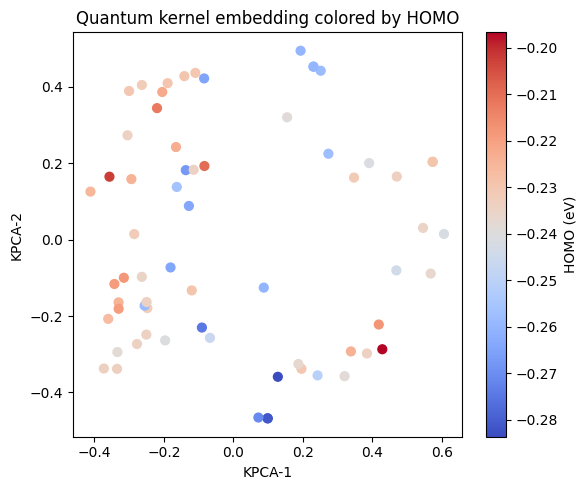

In [50]:
y_train = pipeline.y_train_raw  # or align with chem_df indices

fig, ax = plt.subplots(figsize=(6, 5))
sc = ax.scatter(Z[:,0], Z[:,1],
                c=y_train,
                cmap="coolwarm", s=40)
plt.colorbar(sc, label="HOMO (eV)")
ax.set_title("Quantum kernel embedding colored by HOMO")
ax.set_xlabel("KPCA-1")
ax.set_ylabel("KPCA-2")
plt.tight_layout()

# Save and show
fig_name = "Quantum_kernel_embedding_colored_by_HOMO"
plt.savefig(fig_name, dpi=150, bbox_inches='tight')
plt.show()

## 7.4.3. Substructure enrichment map

In [51]:
from rdkit import Chem

patterns = {
    "aniline": Chem.MolFromSmarts("Nc1ccccc1"),
    "phenol": Chem.MolFromSmarts("Oc1ccccc1"),
    "pyridine": Chem.MolFromSmarts("n1ccccc1"),
    "amide": Chem.MolFromSmarts("C(=O)N"),
    "ester": Chem.MolFromSmarts("C(=O)O"),
    "nitrile": Chem.MolFromSmarts("C#N"),
}

def add_substructure_flags(df):
    mols = [Chem.MolFromSmiles(s) for s in df["smiles"]]
    for name, patt in patterns.items():
        df[name] = [int(m.HasSubstructMatch(patt)) for m in mols]
    return df

In [52]:
chem_train = add_substructure_flags(chem_train)
chem_train["cluster"] = labels

In [53]:
sub_enrich = chem_train.groupby("cluster")[list(patterns.keys())].mean()
sub_enrich

,aniline,phenol,pyridine,amide,ester,nitrile
cluster,,,,,,
0,0.277778,0.388889,0.055556,0.111111,0.111111,0.0
1,0.066667,0.666667,0.066667,0.000000,0.000000,0.0
2,0.000000,0.750000,0.150000,0.050000,0.150000,0.0
3,0.000000,0.615385,0.076923,0.307692,0.307692,0.0


## 7.4.4. Clustering and comparing means

In [54]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=4, random_state=0)
labels = kmeans.fit_predict(Z)

chem_train["cluster"] = labels
chem_train["HOMO"] = y_train

cluster_summary = chem_train.groupby("cluster").agg({
    "HOMO": ["mean", "std"],
    "aromatic_rings": "mean",
    "hetero_atoms": "mean",
    "has_amine_N": "mean",
    "has_EDG": "mean",
    "has_EWG": "mean",
})
cluster_summary

HOMO           aromatic_rings hetero_atoms has_amine_N   has_EDG  \
             mean       std           mean         mean        mean      mean   
cluster                                                                         
0       -0.232890  0.018791       1.000000     1.944444    0.888889  0.944444   
1       -0.245862  0.025576       0.733333     1.733333    0.600000  1.000000   
2       -0.236472  0.014821       1.150000     2.400000    0.600000  1.000000   
3       -0.244415  0.012790       0.692308     1.923077    0.384615  1.000000   

          has_EWG  
             mean  
cluster            
0        0.777778  
1        0.533333  
2        0.600000  
3        0.384615

## 7.4.5. Cluster-by-cluster interpretation
### Cluster 0 — Aromatic donors with moderate heteroatom content
### Cluster 1 — Phenol‑dominated simple aromatics
### Cluster 2 — Phenol + heteroaromatic mix
### Cluster 3 — Strongest EWG/heteroatom enrichment

## 7.4.6. Per‑cluster “prototypes” and “outliers”

In [55]:
def cluster_prototypes(Z, chem_train, k=5):
    reps = {}
    for c in sorted(chem_train["cluster"].unique()):
        mask = chem_train["cluster"] == c
        Zc = Z[mask]
        dists = np.linalg.norm(Zc - Zc.mean(axis=0), axis=1)
        order = np.argsort(dists)
        core = chem_train[mask].iloc[order[:k]]   # core members
        out  = chem_train[mask].iloc[order[-k:]]  # outliers
        reps[c] = {"core": core, "outliers": out}
    return reps

reps = cluster_prototypes(Z, chem_train, k=5)

### Cluster 0 — 5 most central molecules and outliers

In [56]:
print("5 most central molecules of cluster 0")
reps[0]["core"][["smiles", "HOMO", "aromatic_rings", "hetero_atoms"]]

5 most central molecules of cluster 0


,smiles,HOMO,aromatic_rings,hetero_atoms
41,CCN(CC)C1=CC=CC=C1,-0.223071,1,1
38,CCN(CC)C1=CC=C(Br)C=C1,-0.212146,1,2
36,COC1=CC=C(CN2CCOCC2)C=C1,-0.233978,1,3
7,CCN(CC)C1=CC=C(Cl)C=C1,-0.222044,1,2
13,CCOC(=O)N1CCOCC1,-0.267391,0,4


In [57]:
print("Outliers of cluster 0")
reps[0]["outliers"][["smiles", "HOMO", "aromatic_rings", "hetero_atoms"]]

Outliers of cluster 0


,smiles,HOMO,aromatic_rings,hetero_atoms
22,CCOC1=CC=C(CN2CCC2)C=C1,-0.230197,1,2
46,CC1=CC=CC=C1,-0.264688,1,0
32,CCN(CC)C1=CC=C(C)C=C1,-0.202320,1,1
42,CCOC(=O)N1CCNCC1,-0.264240,0,4
63,CN1C=NC2=CC=CC=C12,-0.225455,2,2


###  Cluster 1 — 5 most central molecules and outliers

In [58]:
print("5 most central molecules of cluster 1")
reps[1]["core"][["smiles", "HOMO", "aromatic_rings", "hetero_atoms"]]

5 most central molecules of cluster 1


,smiles,HOMO,aromatic_rings,hetero_atoms
30,CCOC1=CC=C(Cl)C=C1,-0.250952,1,2
39,CCOC1=CC=C(CCN)C=C1,-0.223924,1,2
5,COC1=CC=C(Br)C=C1,-0.238841,1,2
45,CCOC1=CC=C(CN(C)C)C=C1,-0.230360,1,2
56,CCOC1=CC=C(Br)C=C1,-0.236883,1,2


In [59]:
print("Outliers of cluster 1")
reps[1]["outliers"][["smiles", "HOMO", "aromatic_rings", "hetero_atoms"]]

Outliers of cluster 1


,smiles,HOMO,aromatic_rings,hetero_atoms
15,CCN1CCCC1,-0.281630,0,1
4,COC1=CC=CN=C1,-0.260304,1,2
35,CCN1CCCCC1,-0.270978,0,1
3,COC1=CC=C(C=O)C=C1,-0.244121,1,2
37,CCOC1=CC=C(CO)C=C1,-0.236494,1,2


###  Cluster 2 — 5 most central molecules and outliers

In [60]:
print("5 most central molecules of cluster 2")
reps[2]["core"][["smiles", "HOMO", "aromatic_rings", "hetero_atoms"]]

5 most central molecules of cluster 2


,smiles,HOMO,aromatic_rings,hetero_atoms
1,COC1=CC=C(CN2CCCCO2)C=C1,-0.232278,1,3
6,COC1=NC=CC=C1,-0.258686,1,2
61,CCOC1=CC=C(CN2CCCCO2)C=C1,-0.233751,1,3
26,CC1=CC=C(OCCC=O)C=C1,-0.233772,1,2
62,CCOC1=CC=C2N=CC=CC2=C1,-0.219408,2,2


In [61]:
print("Outliers of cluster 2")
reps[2]["outliers"][["smiles", "HOMO", "aromatic_rings", "hetero_atoms"]]

Outliers of cluster 2


,smiles,HOMO,aromatic_rings,hetero_atoms
29,CC1=CC=C(OCCO)C=C1,-0.233597,1,2
11,CCOC(=O)C1=CC=CC=C1,-0.274727,1,2
50,CC1=CC=C(OCCF)C=C1,-0.233476,1,2
65,COC1=CC=C(C(=O)O)C=C1,-0.246633,1,3
2,CCOC1=CC=C(CN2CCOCC2)C=C1,-0.231812,1,3


###  Cluster 3 — 5 most central molecules and outliers

In [62]:
print("5 most central molecules of cluster 3")
reps[3]["core"][["smiles", "HOMO", "aromatic_rings", "hetero_atoms"]]

5 most central molecules of cluster 3


,smiles,HOMO,aromatic_rings,hetero_atoms
25,COC1=CC=CC=C1,-0.241378,1,1
44,COC1=CC=C(C)C=C1,-0.231422,1,1
55,CCOC1=CC=CN=C1,-0.257589,1,2
27,CCOC1=CC=C(F)C=C1,-0.233156,1,2
48,CC1=CC=C(OCC)C=C1,-0.229527,1,1


In [63]:
print("Outliers of cluster 3")
reps[3]["outliers"][["smiles", "HOMO", "aromatic_rings", "hetero_atoms"]]

Outliers of cluster 3


,smiles,HOMO,aromatic_rings,hetero_atoms
64,CCOC(=O)N1CCCC1,-0.259977,0,3
10,CCOC(=O)N1CCCC1,-0.259977,0,3
53,COC1=CC=C(F)C=C1,-0.235343,1,2
52,CCOC(=O)N1CCCCC1,-0.260088,0,3
19,CCOC1=CC=C(C=O)C=C1,-0.242071,1,2


### Plot the kernel‑PCA embedding colored by cluster

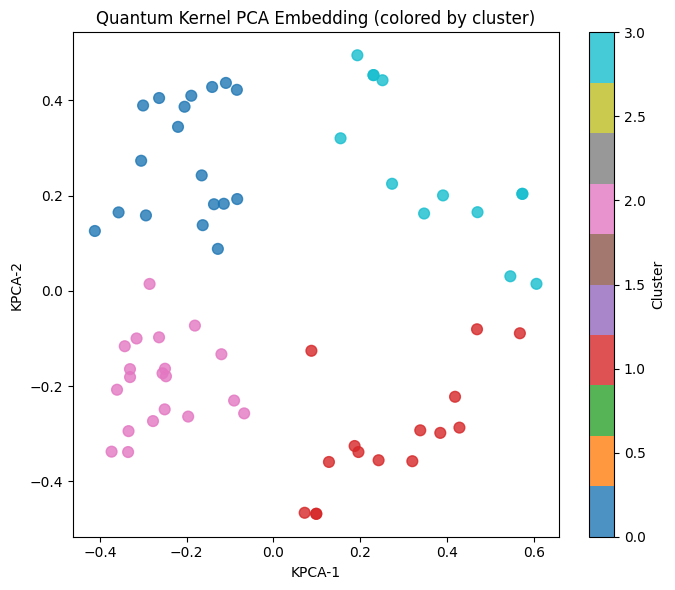

In [64]:
fig, ax = plt.subplots(figsize=(7, 6))

scatter = ax.scatter(
    Z[:, 0], Z[:, 1],
    c=chem_train["cluster"],
    cmap="tab10",
    s=60,
    alpha=0.8
)

plt.colorbar(scatter, label="Cluster")
ax.set_title("Quantum Kernel PCA Embedding (colored by cluster)")
ax.set_xlabel("KPCA-1")
ax.set_ylabel("KPCA-2")
plt.tight_layout()

# Save and show
fig_name = "Quantum_Kernel_PCA_Embedding_colored_by_cluster"
plt.savefig(fig_name, dpi=150, bbox_inches='tight')
plt.show()

### Compute cluster centroids in the embedding

In [65]:
cluster_centroids = (
    chem_train.assign(Z1=Z[:,0], Z2=Z[:,1])
    .groupby("cluster")[["Z1","Z2"]]
    .mean()
)
cluster_centroids

,Z1,Z2
cluster,,
0,-0.203967,0.276318
1,0.269143,-0.302106
2,-0.260375,-0.190699
3,0.372442,0.259374


### Pick representative SMILES for each cluster

In [66]:
representatives = {}

for c in sorted(chem_train["cluster"].unique()):
    mask = chem_train["cluster"] == c
    Zc = Z[mask]
    centroid = cluster_centroids.loc[c].values

    dists = np.linalg.norm(Zc - centroid, axis=1)
    idx = np.argmin(dists)

    # get the SMILES of the representative molecule
    rep_smi = chem_train[mask].iloc[idx]["smiles"]
    representatives[c] = rep_smi

representatives

{np.int32(0): 'CCN(CC)C1=CC=CC=C1',
 np.int32(1): 'CCOC1=CC=C(Cl)C=C1',
 np.int32(2): 'COC1=CC=C(CN2CCCCO2)C=C1',
 np.int32(3): 'COC1=CC=CC=C1'}

### Annotate the embedding with representative SMILES

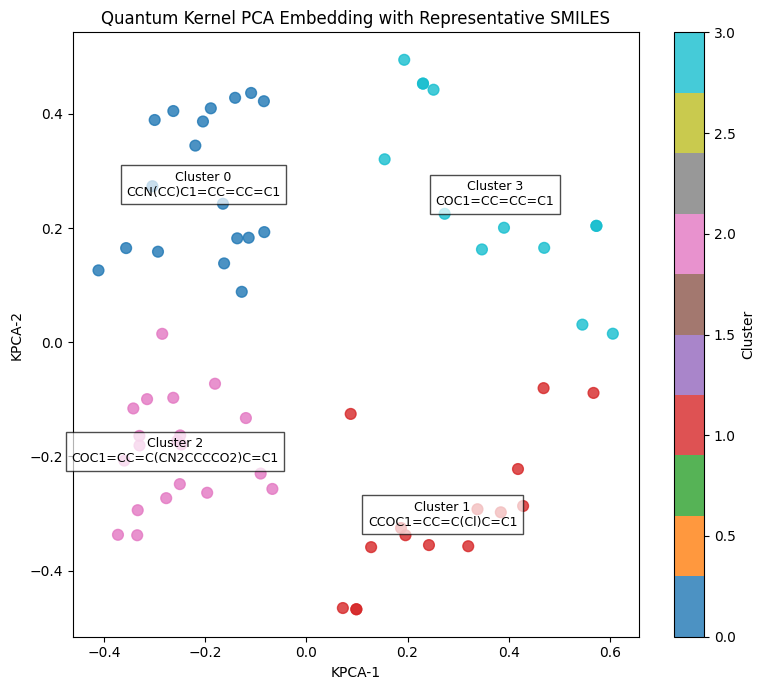

In [67]:
fig, ax = plt.subplots(figsize=(8, 7))

scatter = ax.scatter(
    Z[:, 0], Z[:, 1],
    c=chem_train["cluster"],
    cmap="tab10",
    s=60,
    alpha=0.8
)

for c, smi in representatives.items():
    cx, cy = cluster_centroids.loc[c]
    ax.text(
        cx, cy,
        f"Cluster {c}\n{smi}",
        fontsize=9,
        ha="center",
        va="center",
        bbox=dict(facecolor="white", alpha=0.7, edgecolor="black")
    )

plt.colorbar(scatter, label="Cluster")
ax.set_title("Quantum Kernel PCA Embedding with Representative SMILES")
ax.set_xlabel("KPCA-1")
ax.set_ylabel("KPCA-2")
plt.tight_layout()

# Save and show
fig_name = "Quantum_Kernel_PCA_Embedding_with_Representative_SMILES"
plt.savefig(fig_name, dpi=150, bbox_inches='tight')
plt.show()

### Visualize chemical trends directly

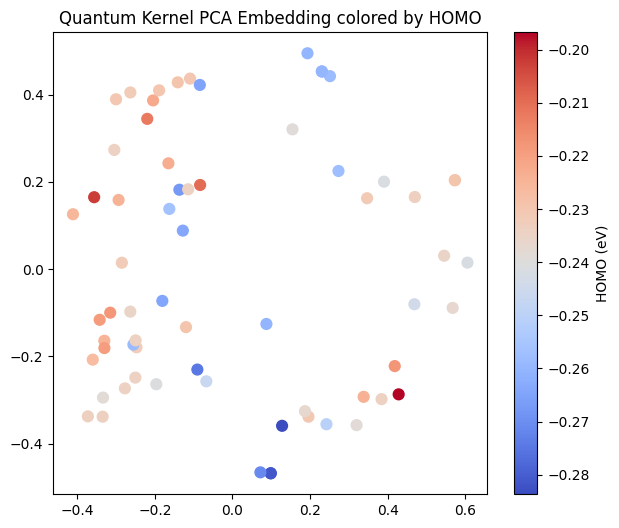

In [68]:
fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(Z[:,0], Z[:,1], c=y_train, cmap="coolwarm", s=60)
plt.colorbar(sc, label="HOMO (eV)")
ax.set_title("Quantum Kernel PCA Embedding colored by HOMO")

# Save and show
fig_name = "Quantum_Kernel_PCA_Embedding_colored_by_HOMO"
plt.savefig(fig_name, dpi=150, bbox_inches='tight')
plt.show()

### Overlay HOMO and substructures on the embedding

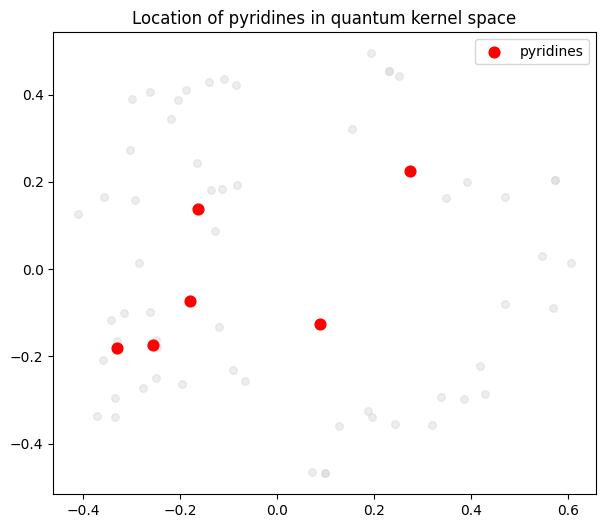

In [69]:
mask_pyr = chem_train["pyridine"] == 1

plt.figure(figsize=(7,6))
plt.scatter(Z[:,0], Z[:,1], c="lightgray", s=30, alpha=0.4)
plt.scatter(Z[mask_pyr,0], Z[mask_pyr,1], c="red", s=60, label="pyridines")
plt.legend()
plt.title("Location of pyridines in quantum kernel space")

# Save and show
fig_name = "Location_of_pyridines_in_quantum_kernel_space"
plt.savefig(fig_name, dpi=150, bbox_inches='tight')
plt.show()

### Local “neighborhood” explanations

In [70]:
i = 0  # index of molecule of interest in training set
row = K[i]              # similarities to all others
nn_idx = np.argsort(-row)[1:6]  # top 5 neighbors (excluding itself)

chem_train.iloc[[i]][["smiles","HOMO","cluster"]]
chem_train.iloc[nn_idx][["smiles","HOMO","cluster"]]

,smiles,HOMO,cluster
28,CCOC1=NC=CC=C1,-0.256341,0
34,CCOC1=CC=CC=C1,-0.238995,3
6,COC1=NC=CC=C1,-0.258686,2
59,CC1=CC=C(OCCC)C=C1,-0.229358,2
44,COC1=CC=C(C)C=C1,-0.231422,3


## 7.4.7. Visualizing clusters vs substructures

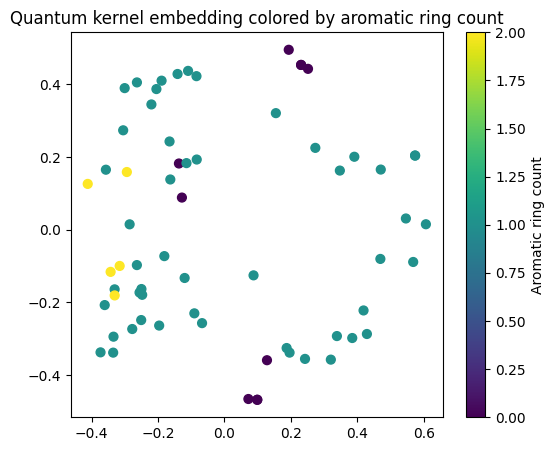

In [71]:
fig, ax = plt.subplots(figsize=(6, 5))
sc = ax.scatter(
    Z[:,0], Z[:,1],
    c=chem_train["aromatic_rings"],   # <-- now length matches Z
    cmap="viridis",
    s=40
)
ax.set_title("Quantum kernel embedding colored by aromatic ring count")
plt.colorbar(sc, label="Aromatic ring count")

fig_name = "Quantum_kernel_embedding_colored_by_aromatic_ring_count"
plt.savefig(fig_name, dpi=150, bbox_inches='tight')
plt.show()

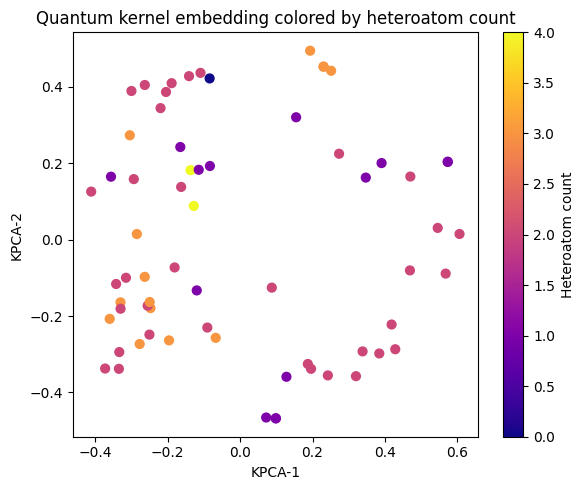

In [72]:
fig, ax = plt.subplots(figsize=(6, 5))
sc = ax.scatter(Z[:,0], Z[:,1],
                c=chem_train["hetero_atoms"],   # <-- now length matches Z
                cmap="plasma", s=40)
plt.colorbar(sc, label="Heteroatom count")
ax.set_title("Quantum kernel embedding colored by heteroatom count")
ax.set_xlabel("KPCA-1")
ax.set_ylabel("KPCA-2")
plt.tight_layout()

fig_name = "Quantum_kernel_embedding_colored_by_heteroatom_count"
plt.savefig(fig_name, dpi=150, bbox_inches='tight')
plt.show()

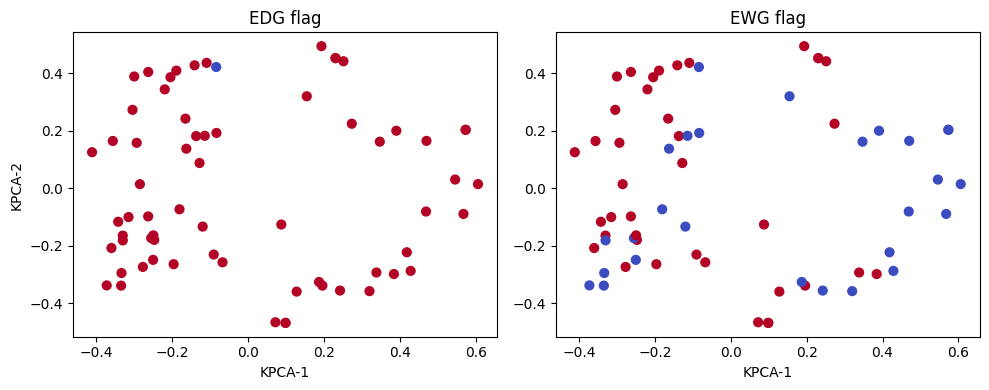

In [73]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

# EDG
ax[0].scatter(Z[:,0], Z[:,1],
              c=chem_train["has_EDG"].astype(int),
              cmap="coolwarm", s=40)
ax[0].set_title("EDG flag")
ax[0].set_xlabel("KPCA-1")
ax[0].set_ylabel("KPCA-2")

# EWG
ax[1].scatter(Z[:,0], Z[:,1],
              c=chem_train["has_EWG"].astype(int),
              cmap="coolwarm", s=40)
ax[1].set_title("EWG flag")
ax[1].set_xlabel("KPCA-1")

plt.tight_layout()

fig_name = "EDG_vs_EWG"
plt.savefig(fig_name, dpi=150, bbox_inches='tight')
plt.show()

# 7.5. Variational Quantum Neural Networks (QNNs)

## 7.5.1. Running pipeline in EstimatorQNN mode
# Patch optimizer so callback works
# Train using Qiskit Machine Learning's NeuralNetworkRegressor

In [74]:
def plot_history(hist, title):
    if not hist:
        return

    plt.figure(figsize=(6.2, 4.2))
    plt.plot(hist, marker='o', markersize=3, linewidth=1, label="Loss")
    plt.xlabel("Iteration")
    plt.ylabel("Loss")
    plt.title(title)
    plt.grid(True)
    plt.legend()
    plt.tight_layout()

    plt.savefig(title, dpi=150, bbox_inches='tight')
    plt.show()

In [75]:
history = []

def cb(eval_count, params, mean, std):
    history.append(float(mean))

In [76]:
pipeline = QiskitQMLPipeline(
    mode="estimator",
    max_qubits=8,
    max_pca=5,
    reps=2,
    optimizer=SPSA(maxiter=400),
    entanglement_QNN='circular',
    callback=cb
)

pipeline.fit(X, y)
print("EstimatorQNN regression:", pipeline.score())

print(f"\n{len(history)} callback entries")
print(history[:10])

R² = 0.4019, MAE = 0.0126
EstimatorQNN regression: 0.40191703869357187

851 callback entries
[1.0359370398334486, 0.9684339959468374, 0.9824977798138408, 1.036831227540663, 1.0508912811197675, 0.9551883692813012, 1.0626497025908759, 0.9193822792713506, 1.0225137465881948, 0.9756442019681607]


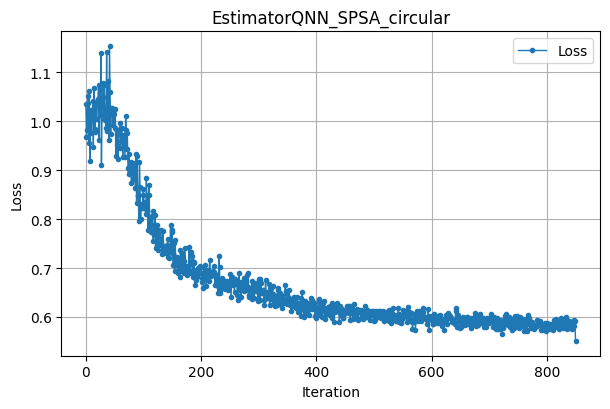

In [77]:
plot_history(history, "EstimatorQNN_SPSA_circular")

# Conclusion

# References
[ASE_0] Atomic Simulation Environment (ASE), https://wiki.fysik.dtu.dk/ase/index.html

[H5py] Quick Start Guide, https://docs.h5py.org/en/stable/quick.html 

[Loredo_Qiskit] Robert Loredo, Chapter 3: Introducing and Installing Qiskit. Learn Quantum Computing with Python and IBM Quantum, Packt Publishing, 2025. ISBN 978-1803244808, https://www.amazon.fr/Learn-Quantum-Computing-Python-IBM/dp/1803244801/

[NumPy] NumPy: the absolute basics for beginners, https://numpy.org/doc/stable/user/absolute_beginners.html

[PyQMC] PyQMC, a python module that implements real-space quantum Monte Carlo techniques, https://github.com/WagnerGroup/pyqmc 

[PySCF] The Python-based Simulations of Chemistry Framework (PySCF), https://pyscf.org/

[Qiskit] Qiskit, https://qiskit.org/

[Qiskit_Aer_1] Qiskit Aer documentation, https://qiskit.github.io/qiskit-aer/ 

[Qiskit_Aer_2] NoiseModel, https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.noise.NoiseModel.html 

[QML_1] Qiskit Machine Learning, https://github.com/qiskit-community/qiskit-machine-learning 

[Qiskit_Nat_0] Qiskit_Nature, https://github.com/Qiskit/qiskit-nature/blob/main/README.md 

[Qiskit_Nature] Qiskit Nature overview, Qiskit Nature 0.7.2, https://qiskit-community.github.io/qiskit-nature/

[QuTiP] QuTiP, Plotting on the Bloch Sphere, https://qutip.readthedocs.io/en/qutip-5.0.x/guide/guide-bloch.html

[SciPy] Statistical functions (scipy.stats), https://projects.scipy.org/getting-started.html

[sklearn_PCA] Principal component analysis (PCA), https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html 

[sklearn_SVM] Support Vector Machines, https://scikit-learn.org/stable/auto_examples/svm/index.html 

[sklearn_SVR_1] Support Vector Regression (SVR) using linear and non-linear kernels, https://scikit-learn.org/stable/auto_examples/svm/plot_svm_regression.html 

[sklearn_SVR_2] SVR, Epsilon-Support Vector Regression, https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVR.html

## Qiskit packages versions

In [6]:
import qiskit
import qiskit_ibm_runtime
import qiskit_aer
import qiskit_machine_learning

print(f'Qiskit: {qiskit.__version__}')
print(f'Qiskit IBM Runtime: {qiskit_ibm_runtime.__version__}')
print(f"Qiskit Aer: {qiskit_aer.__version__}")
print(f"Qiskit Machine Learning: {qiskit_machine_learning.__version__}")

Qiskit: 2.3.0
Qiskit IBM Runtime: 0.45.1
Qiskit Aer: 0.17.2
Qiskit Machine Learning: 0.9.0


## Qiskit Algorithms

In [7]:
import qiskit_algorithms
print(f"Qiskit Algorithms version: {qiskit_algorithms.__version__}")

Qiskit Algorithms version: 0.4.0


## scikit-learn

In [8]:
import sklearn
sklearn.show_versions()


System:
    python: 3.13.12 | packaged by Anaconda, Inc. | (main, Feb 24 2026, 16:13:31) [GCC 14.3.0]
executable: /home/alain/miniconda3/bin/python3.13
   machine: Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-with-glibc2.39

Python dependencies:
      sklearn: 1.8.0
          pip: 26.0.1
   setuptools: 80.10.2
        numpy: 2.3.5
        scipy: 1.17.1
       Cython: None
       pandas: 2.3.3
   matplotlib: 3.10.8
       joblib: 1.5.3
threadpoolctl: 3.6.0

Built with OpenMP: True

threadpoolctl info:
       user_api: blas
   internal_api: openblas
    num_threads: 22
         prefix: libopenblas
       filepath: /home/alain/miniconda3/lib/libopenblasp-r0.3.30.so
        version: 0.3.30
threading_layer: pthreads
   architecture: Haswell

       user_api: blas
   internal_api: openblas
    num_threads: 1
         prefix: libopenblas
       filepath: /home/alain/miniconda3/lib/python3.13/site-packages/qiskit_aer.libs/libopenblas-r0-f650aae0.3.3.so
        version: None
threading_layer: 

## Python

In [9]:
# Display Python version
!python --version

Python 3.13.12
